# 第 4 章 随机游走 — 代码实验

对照教材：Shonkwiler & Mendivil《Explorations in Monte Carlo Methods》第 4 章（§4.1–4.8）。

13 个实验，输出图 `out-4-M.png`。随机种子 2027。

In [1]:
# ===== 公共设置 =====
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

rng = np.random.default_rng(2027)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch04")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

print("numpy", np.__version__)

numpy 2.4.6


## 实验 1 30 步公平游走终点直方图（书 §4.1，Alg 4.1，Fig 4.1）

20 万条游走；验证 E(S_n)=0、var(S_n)=n·Δx²（式 (4.2)(4.3) 的 p=q=1/2 情形）。

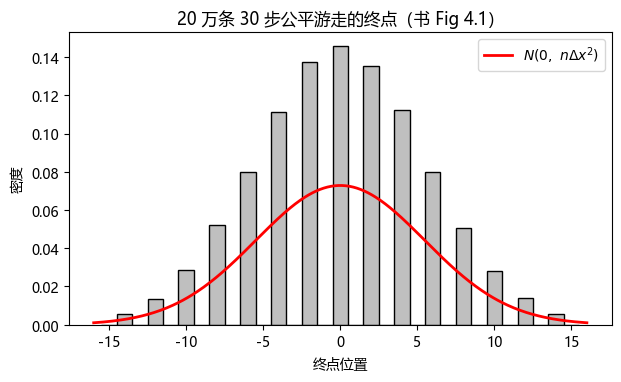

均值 -0.009（理论 0），方差 30.136（理论 30）


In [2]:
# ===== 书 §4.1 Alg 4.1 =====
nSteps, nTrials = 30, 200_000
T = 2*(rng.random((nTrials, nSteps)) < 0.5) - 1
H = T.sum(axis=1)

fig, ax = plt.subplots(figsize=(7, 3.8))
vals = np.arange(-16, 18, 2)
ax.hist(H, bins=np.arange(-15.5, 16.5), density=True, color="0.75", edgecolor="k")
xs = np.linspace(-16, 16, 400)
ax.plot(xs, np.exp(-xs**2/(2*nSteps))/np.sqrt(2*np.pi*nSteps), "r-", lw=2,
        label=r"$N(0,\ n\Delta x^2)$")
ax.set_xlabel("终点位置"); ax.set_ylabel("密度")
ax.set_title("20 万条 30 步公平游走的终点（书 Fig 4.1）"); ax.legend()
save(fig, "out-4-1.png"); plt.show()
print(f"均值 {H.mean():.3f}（理论 0），方差 {H.var():.3f}（理论 {nSteps}）")

## 实验 2 漂移游走（书 §4.1 式 (4.2)(4.3)；习题 8）

p=0.6 偏置硬币：E(S₃₀)=30(0.6−0.4)Δx=6、var=4·30·0.6·0.4=28.8。

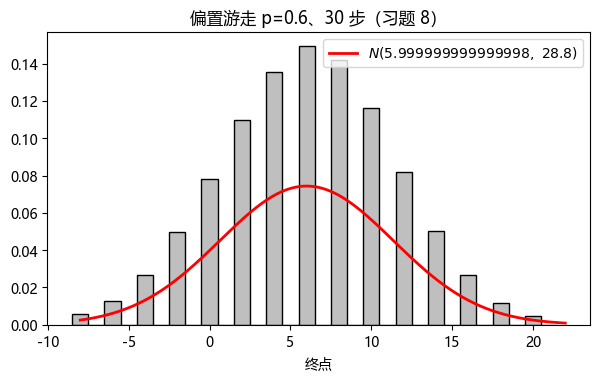

实测 均值 6.004（5.999999999999998），方差 28.755（28.8）


In [3]:
# ===== 书 §4.1 式 (4.2)(4.3) =====
p = 0.6
T = np.where(rng.random((100_000, nSteps)) < p, 1.0, -1.0)
H = T.sum(axis=1)
mu_t = nSteps*(2*p-1); var_t = 4*nSteps*p*(1-p)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(H, bins=np.arange(-8.5, 22.5), density=True, color="0.75", edgecolor="k")
xs = np.linspace(-8, 22, 400)
ax.plot(xs, np.exp(-(xs-mu_t)**2/(2*var_t))/np.sqrt(2*np.pi*var_t), "r-", lw=2,
        label=f"$N({mu_t},\\ {var_t:.1f})$")
ax.set_title("偏置游走 p=0.6、30 步（习题 8）"); ax.set_xlabel("终点"); ax.legend()
save(fig, "out-4-2.png"); plt.show()
print(f"实测 均值 {H.mean():.3f}（{mu_t}），方差 {H.var():.3f}（{var_t:.1f}）")

## 实验 3 一维常返性（书 §4.1，Fig 4.2）

10 万条游走全部回访原点（比例=1）；首返时间重尾（对数 y 轴）——常返但平均首返时间无穷。

N=4000 步内回访比例 = 0.9878；首返中位 = 2 步


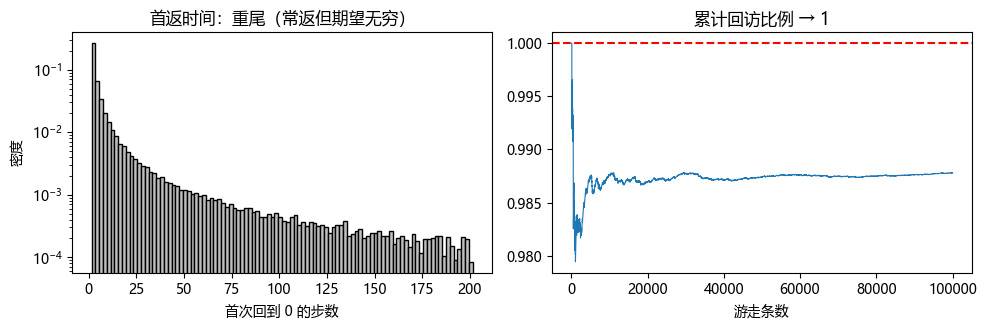

In [4]:
# ===== 书 §4.1 常返性 =====
Nw, Ns = 100_000, 4000
steps = np.where(rng.random((Nw, Ns)) < 0.5, 1, -1)
pos = steps.cumsum(axis=1)
hit0 = (pos == 0)
first = np.where(hit0.any(axis=1), hit0.argmax(axis=1)+1, -1)
frac_return = np.mean(first > 0)
ft = first[first > 0]
print(f"N={Ns} 步内回访比例 = {frac_return:.4f}；首返中位 = {np.median(ft):.0f} 步")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(ft, bins=np.arange(1.5, 202, 2), density=True, color="0.75", edgecolor="k")
ax[0].set_yscale("log"); ax[0].set_xlabel("首次回到 0 的步数"); ax[0].set_ylabel("密度")
ax[0].set_title("首返时间：重尾（常返但期望无穷）")
run = np.cumsum((first > 0).astype(float))/np.arange(1, Nw+1)
ax[1].plot(run, lw=0.8); ax[1].axhline(1.0, color="r", ls="--")
ax[1].set_xlabel("游走条数"); ax[1].set_title("累计回访比例 → 1")
plt.tight_layout(); save(fig, "out-4-3.png"); plt.show()

## 实验 4 扩散标度坍缩（书 §4.2，式 (4.6)(4.7)）

三组 (Δx, Δt) 保持 D=Δx²/2Δt 不变 → 终点分布坍缩到同一极限密度。

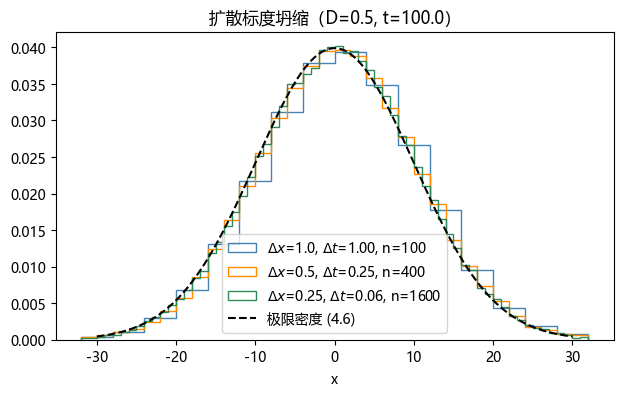

三组步数 n = [100, 400, 1600]


In [5]:
# ===== 书 §4.2 扩散 =====
D = 0.5
Tfix, nT = 100.0, 100_000     # t 取大值，保证每组步数足够多才谈“极限”
fig, ax = plt.subplots(figsize=(7.2, 4))
for dx, c in [(1.0, "steelblue"), (0.5, "darkorange"), (0.25, "seagreen")]:
    dt = dx*dx/(2*D)
    n = max(1, int(round(Tfix/dt)))
    steps = np.where(rng.random((nT, n)) < 0.5, dx, -dx)
    end = steps.sum(axis=1)
    edges = np.arange(-32, 32 + 4*dx, 4*dx)   # bin 宽 4Δx ≥ 格距，避免梳齿伪影
    ax.hist(end, bins=edges, density=True, histtype="step",
            lw=1.6, color=c, label=f"$\\Delta x$={dx}, $\\Delta t$={dt:.2f}, n={n}")
xs = np.linspace(-30, 30, 400)
ax.plot(xs, np.exp(-xs**2/(4*D*Tfix))/np.sqrt(4*np.pi*D*Tfix), "k--", lw=1.5,
        label="极限密度 (4.6)")
ax.set_title(f"扩散标度坍缩（D={D}, t={Tfix}）"); ax.set_xlabel("x"); ax.legend()
save(fig, "out-4-4.png"); plt.show()
print("三组步数 n =", [int(round(Tfix/(dx*dx/(2*D)))) for dx in (1.0, 0.5, 0.25)])

## 实验 5 二维布朗运动（书 §4.3，Alg 4.2，Fig 4.3）

随机方向 + 正态步长；两级放大看自相似；400 条终点散点 = 二维正态。

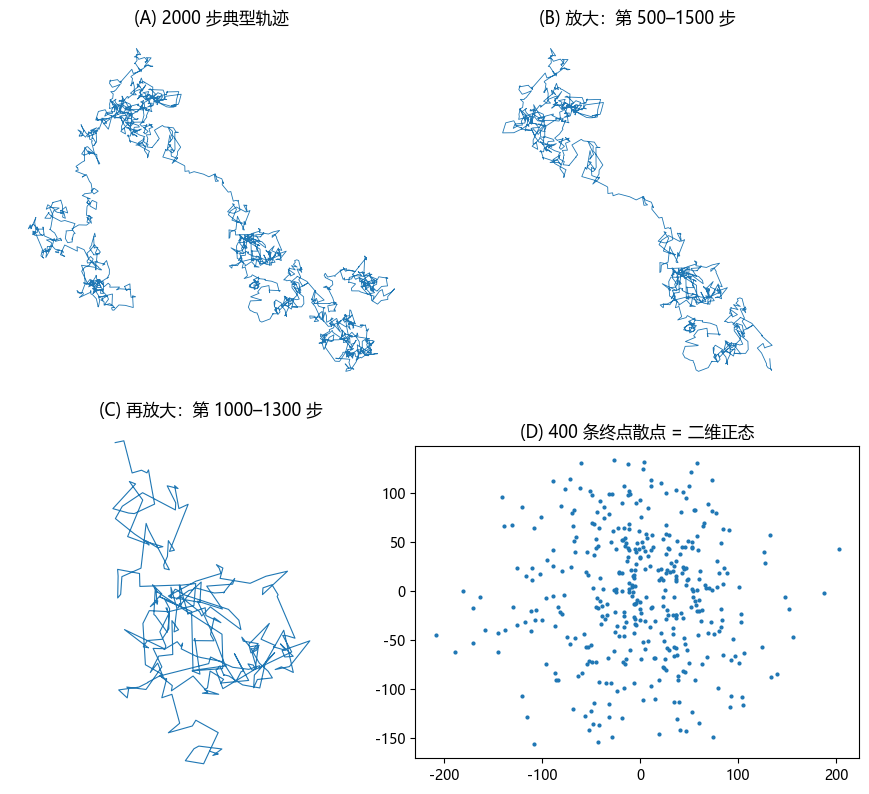

In [6]:
# ===== 书 §4.3 Alg 4.2 =====
def bm2d(nSteps, sigma=2.0):
    th = 2*np.pi*rng.random(nSteps)
    mag = rng.normal(0, sigma, nSteps)
    dx, dy = mag*np.cos(th), mag*np.sin(th)
    return np.concatenate([[0], dx]).cumsum(), np.concatenate([[0], dy]).cumsum()

x, y = bm2d(2000)
fig, ax = plt.subplots(2, 2, figsize=(9, 8))
ax[0,0].plot(x, y, lw=0.6); ax[0,0].set_title("(A) 2000 步典型轨迹")
ax[0,1].plot(x[500:1500], y[500:1500], lw=0.6); ax[0,1].set_title("(B) 放大：第 500–1500 步")
ax[1,0].plot(x[1000:1300], y[1000:1300], lw=0.8); ax[1,0].set_title("(C) 再放大：第 1000–1300 步")
for a in ax.flat[:3]: a.set_aspect("equal"); a.axis("off")
ex, ey = np.empty(400), np.empty(400)
for j in range(400):
    ex[j], ey[j] = bm2d(2000)[0][-1], bm2d(2000)[1][-1]
ax[1,1].scatter(ex, ey, s=4); ax[1,1].set_title("(D) 400 条终点散点 = 二维正态")
ax[1,1].set_aspect("equal")
plt.tight_layout(); save(fig, "out-4-5.png"); plt.show()

## 实验 6 Pólya 定理：维度生死线（书 §4.3，定理 4.1）

d=1,2 常返（回访比例 →1），d=3 非常返（卡在 ≈0.34）。

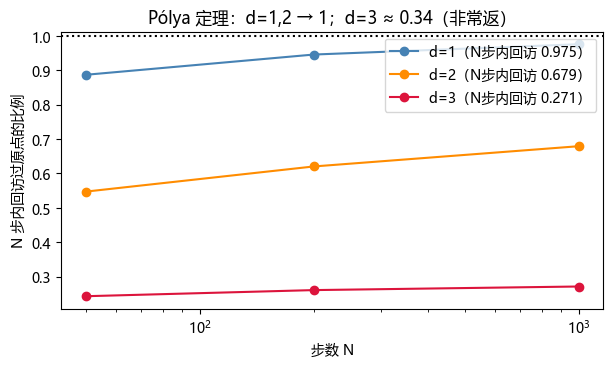

In [7]:
# ===== Pólya =====
def return_frac(d, nWalks=20_000, nSteps=1000):
    steps = 2*rng.integers(0, 2, (nWalks, nSteps, d)) - 1
    pos = steps.cumsum(axis=1)
    hit = (pos == 0).all(axis=2)
    return np.mean(hit.any(axis=1)), [np.mean(hit[:, :k].any(axis=1)) for k in (50, 200, 1000)]

fig, ax = plt.subplots(figsize=(7, 3.6))
for d, c in [(1, "steelblue"), (2, "darkorange"), (3, "crimson")]:
    fr, pts = return_frac(d)
    ax.plot([50, 200, 1000], pts, "o-", color=c, label=f"d={d}（N步内回访 {fr:.3f}）")
ax.axhline(1.0, ls=":", color="k")
ax.set_xscale("log"); ax.set_xlabel("步数 N"); ax.set_ylabel("N 步内回访过原点的比例")
ax.set_title("Pólya 定理：d=1,2 → 1；d=3 ≈ 0.34（非常返）"); ax.legend()
save(fig, "out-4-6.png"); plt.show()

## 实验 7 期权定价 vs Black–Scholes（书 §4.4.1，Alg 4.3，Fig 4.4）

S₀=20, X=25, σ=0.6, r=0.031, T=90/365。风险中性 μ=r；对照 BS 精确值 0.9056。

模拟期权价 = 0.8933
Black–Scholes 精确值 = 0.9056（书 0.9056）


C:\Users\17272\AppData\Local\Temp\ipykernel_122608\4266018365.py:40: UserWarning: Glyph 8329 (\N{SUBSCRIPT NINE}) missing from font(s) Microsoft YaHei.
  plt.tight_layout(); save(fig, "out-4-7.png"); plt.show()
C:\Users\17272\AppData\Local\Temp\ipykernel_122608\4266018365.py:40: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Microsoft YaHei.
  plt.tight_layout(); save(fig, "out-4-7.png"); plt.show()
C:\Users\17272\AppData\Local\Temp\ipykernel_122608\3680643069.py:13: UserWarning: Glyph 8329 (\N{SUBSCRIPT NINE}) missing from font(s) Microsoft YaHei.
  fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")
C:\Users\17272\AppData\Local\Temp\ipykernel_122608\3680643069.py:13: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Microsoft YaHei.
  fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")


C:\Anocanda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8329 (\N{SUBSCRIPT NINE}) missing from font(s) Microsoft YaHei.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Anocanda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Microsoft YaHei.
  fig.canvas.print_figure(bytes_io, **kw)


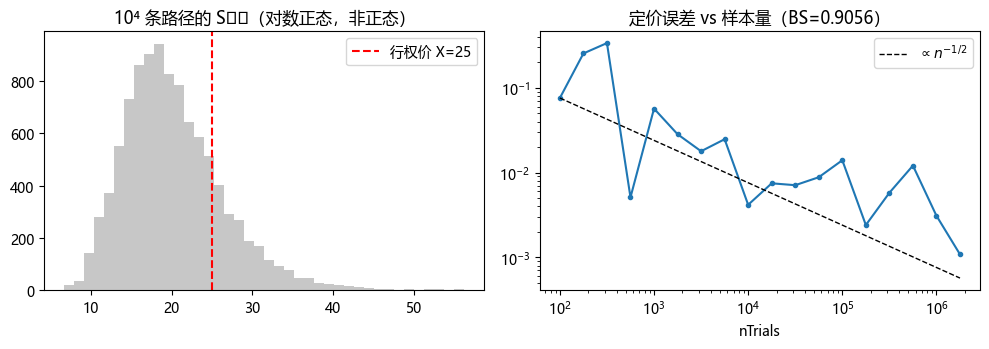

In [8]:
# ===== 书 §4.4.1 Alg 4.3 =====
from math import log, sqrt, erf
nDays, dt = 90, 1/365.0
T = nDays*dt; S0, X, r, sigma = 20, 25, 0.031, 0.6
expTerm, stddev = r*dt, sigma*np.sqrt(dt)
nTrials = 10_000
S90 = np.empty(nTrials); values = np.empty(nTrials)
for j in range(nTrials):
    Nv = rng.standard_normal(nDays)
    S = S0
    for i in range(nDays):
        dS = S*(expTerm + stddev*Nv[i])
        S += dS
    S90[j] = S
    values[j] = max(S - X, 0)
price = np.exp(-r*T)*values.mean()
print(f"模拟期权价 = {price:.4f}")

def normcdf(z): return 0.5*(1+erf(z/np.sqrt(2)))
d1 = (log(S0/X)+(r+sigma**2/2)*T)/(sigma*np.sqrt(T))
d2 = (log(S0/X)+(r-sigma**2/2)*T)/(sigma*np.sqrt(T))
bs = S0*normcdf(d1) - X*np.exp(-r*T)*normcdf(d2)
print(f"Black–Scholes 精确值 = {bs:.4f}（书 0.9056）")

# 收敛：批量累积
def mc_price(n):
    Nv = rng.standard_normal((n, nDays))
    logS = np.log(S0) + (r-0.5*sigma**2)*nDays*dt + sigma*np.sqrt(dt)*Nv.sum(axis=1)
    return np.exp(-r*T)*np.maximum(np.exp(logS)-X, 0).mean()
ns = 10**np.arange(2, 6.5, 0.25)
errs = [abs(mc_price(int(n))-bs) for n in ns]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(S90, bins=40, color="0.78", edgecolor="none")
ax[0].axvline(X, color="r", ls="--", label="行权价 X=25")
ax[0].set_title(f"10⁴ 条路径的 S₉₀（对数正态，非正态）"); ax[0].legend()
ax[1].loglog(ns, errs, "o-", ms=3)
ref = errs[0]*(ns/ns[0])**(-0.5)
ax[1].loglog(ns, ref, "k--", lw=1, label=r"$\propto n^{-1/2}$")
ax[1].set_title(f"定价误差 vs 样本量（BS={bs:.4f}）"); ax[1].legend(); ax[1].set_xlabel("nTrials")
plt.tight_layout(); save(fig, "out-4-7.png"); plt.show()

## 实验 8 赌徒破产：模拟 vs 精确解（书 §4.5，式 (4.12)(4.13)(4.16)）

公平局 r_x=1−x/a、T(x)=x(a−x)；偏置局用 (4.12)。

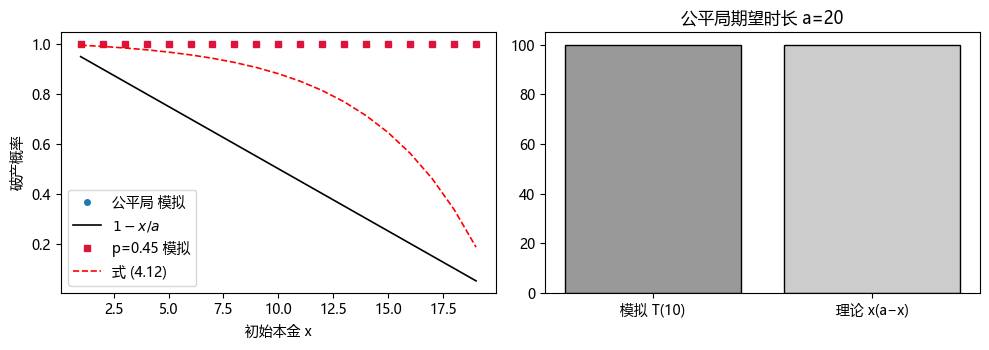

In [9]:
# ===== 书 §4.5 赌徒破产 =====
def ruin_sim(x, a, p, reps=200_000):
    fortune = np.full(reps, x); alive = np.ones(reps, bool); T = np.zeros(reps)
    while alive.any():
        idx = np.where(alive)[0]
        fortune[idx] += np.where(rng.random(len(idx)) < p, 1, -1)
        T[idx] += 1
        alive[idx] = (fortune[idx] > 0) & (fortune[idx] < a)
    return np.mean(fortune[fortune <= 0] <= 0), T.mean()

a = 20
xs = np.arange(1, a)
r_fair_sim = [ruin_sim(x, a, 0.5, 50_000)[0] for x in xs]
r_fair_theory = 1 - xs/a
r_biased_sim = [ruin_sim(x, a, 0.45, 50_000)[0] for x in xs]
qb, pb = 0.55, 0.45
r_biased_theory = ((qb/pb)**a - (qb/pb)**xs)/((qb/pb)**a - 1)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(xs, r_fair_sim, "o", ms=4, label="公平局 模拟")
ax[0].plot(xs, r_fair_theory, "k-", lw=1.2, label=r"$1-x/a$")
ax[0].plot(xs, r_biased_sim, "s", ms=4, color="crimson", label="p=0.45 模拟")
ax[0].plot(xs, r_biased_theory, "r--", lw=1.2, label=r"式 (4.12)")
ax[0].set_xlabel("初始本金 x"); ax[0].set_ylabel("破产概率"); ax[0].legend()
_, Tfair = ruin_sim(10, a, 0.5, 100_000)
ax[1].bar(["模拟 T(10)", r"理论 x(a−x)"], [Tfair, 10*(a-10)], color=["0.6", "0.8"], edgecolor="k")
ax[1].set_title(f"公平局期望时长 a={a}")
plt.tight_layout(); save(fig, "out-4-8.png"); plt.show()

## 实验 9 倍押 vs 平押（书 §4.5.1）

$1023 本金、目标赢 $1、轮盘 p=18/38。倍押 99.8% 达成（期望 −$0.66），平押 90%（−$101.40）。

平押:   达成率 0.8988，期望收益 $-102.63（书 −$101.40）
倍押:   达成率 0.9988，期望收益 $-0.23（书 −$0.66）


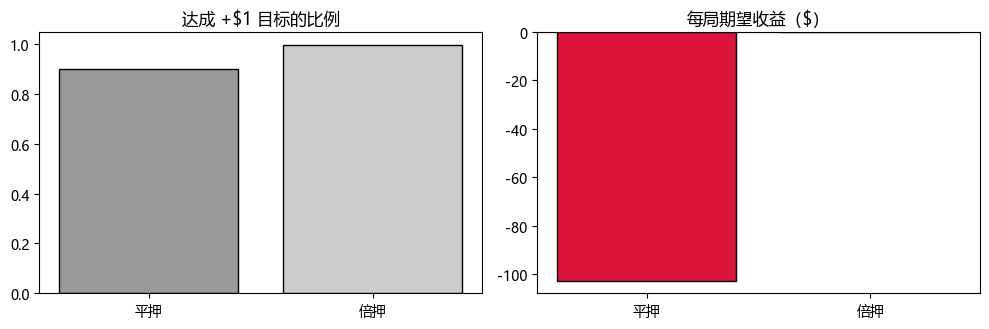

In [10]:
# ===== 书 §4.5.1 =====
p = 18/38; bank = 1023; goal = 1
def flat(reps=20_000):
    wins = 0; profit = 0.0
    for _ in range(reps):
        f = bank
        while 0 < f < bank+goal:
            f += 1 if rng.random() < p else -1
        if f >= bank+goal: wins += 1; profit += goal
        else: profit -= bank
    return wins/reps, profit/reps
def doubling(reps=20_000):
    wins = 0; profit = 0.0
    for _ in range(reps):
        bet = 1; lost = 0
        while True:
            if rng.random() < p:
                profit += bet - lost if False else goal  # 总收益恰 $1
                wins += 1; break
            lost += bet; bet *= 2
            if lost + bet > bank:      # 押不起了：输光
                profit -= bank; break
    return wins/reps, profit/reps
w1, pr1 = flat(); w2, pr2 = doubling()
print(f"平押:   达成率 {w1:.4f}，期望收益 ${pr1:.2f}（书 −$101.40）")
print(f"倍押:   达成率 {w2:.4f}，期望收益 ${pr2:.2f}（书 −$0.66）")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(["平押", "倍押"], [w1, w2], color=["0.6", "0.8"], edgecolor="k")
ax[0].set_title("达成 +$1 目标的比例"); ax[0].set_ylim(0, 1.05)
ax[1].bar(["平押", "倍押"], [pr1, pr2], color=["crimson", "darkorange"], edgecolor="k")
ax[1].axhline(0, color="k", lw=0.8); ax[1].set_title("每局期望收益（$）")
plt.tight_layout(); save(fig, "out-4-9.png"); plt.show()

## 实验 10 Kelly 简单游戏（书 §4.6.1，Alg 4.4，Fig 4.5/4.6）

60/40 游戏、γ=1：理论 f*=0.2；扫描 g(f) 验证峰值位置。

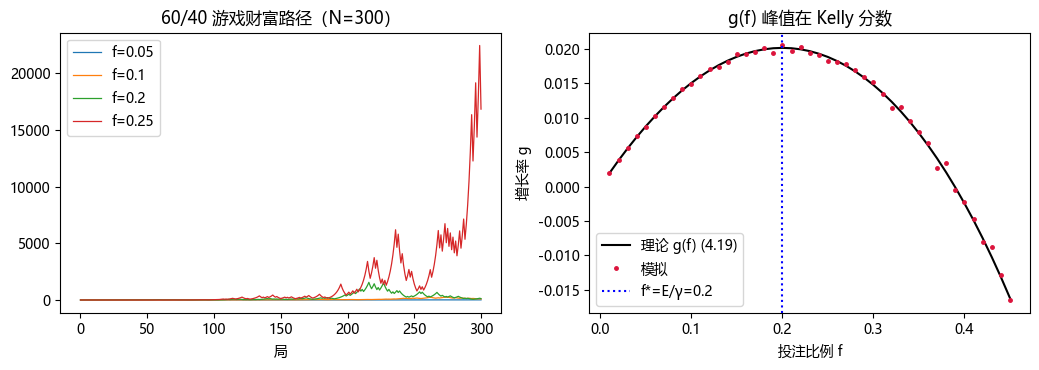

In [11]:
# ===== 书 §4.6.1 Alg 4.4 =====
pk, qk = 0.6, 0.4
def kelly_path(f, N=300):
    Fv = 1.0; h = [Fv]
    for _ in range(N):
        w = Fv*f
        Fv = Fv + w if rng.random() < pk else Fv - w
        h.append(Fv)
    return h
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
for f, c in zip([0.05, 0.1, 0.2, 0.25], ["C0", "C1", "C2", "C3"]):
    ax[0].plot(kelly_path(f), lw=0.9, color=c, label=f"f={f}")
ax[0].set_title("60/40 游戏财富路径（N=300）"); ax[0].legend(); ax[0].set_xlabel("局")
fs = np.linspace(0.01, 0.45, 45)
g_theory = pk*np.log(1+fs) + qk*np.log(1-fs)
g_sim = []
for f in fs:
    ends = []
    for _ in range(300):
        ends.append(kelly_path(f, 1000)[-1])
    g_sim.append(np.mean(np.log(ends))/1000)
ax[1].plot(fs, g_theory, "k-", lw=1.5, label="理论 g(f) (4.19)")
ax[1].plot(fs, g_sim, ".", ms=5, color="crimson", label="模拟")
ax[1].axvline(0.2, ls=":", color="b", label="f*=E/γ=0.2")
ax[1].set_xlabel("投注比例 f"); ax[1].set_ylabel("增长率 g")
ax[1].set_title("g(f) 峰值在 Kelly 分数"); ax[1].legend()
plt.tight_layout(); save(fig, "out-4-10.png"); plt.show()

## 实验 11 灾难损失游戏（书 §4.6.2，式 (4.21)(4.22)）

γ₁=4, λ₂=1, λ₃=4, p=(1/2,1/4,1/4)：f*=0.0625（线性近似 0.0577）；f>1/4 爆仓区。

C:\Users\17272\AppData\Local\Temp\ipykernel_122608\3492105783.py:21: RuntimeWarning: divide by zero encountered in log
  g_sim.append(np.mean(np.log(ends))/2000)


精确 f* = 0.0625（书 0.0625）；线性近似 = 0.0577


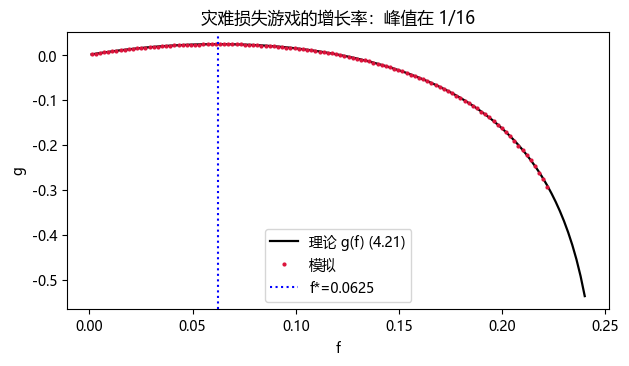

In [12]:
# ===== 书 §4.6.2 =====
p1, p2, p3 = 0.5, 0.25, 0.25
g1, l2, l3 = 4.0, 1.0, 4.0
E = p1*g1 - p2*l2 - p3*l3
def g_exact(f):
    f = np.asarray(f, float)
    out = p1*np.log(1+f*g1) + p2*np.log(1-f*l2) + p3*np.log(1-f*l3)
    return np.where(f < 1/l3, out, -np.inf)
fs = np.linspace(0.001, 0.24, 120)
g_sim = []
for f in fs:
    ends = []
    for _ in range(400):
        X = 1.0
        for _ in range(2000):
            u = rng.random()
            if u < p1: X *= 1 + f*g1
            elif u < p1+p2: X *= 1 - f*l2
            else: X *= 1 - f*l3
        ends.append(X)
    g_sim.append(np.mean(np.log(ends))/2000)
fq = np.roots([g1*l2*l3, -(p1*g1*(l2+l3)+p2*l2*(g1-l3)+p3*l3*(g1-l2)), E])
fstar = min(r for r in fq if 0 < r < 1/4)
print(f"精确 f* = {fstar:.4f}（书 0.0625）；线性近似 = {E/(p1*g1*(l2+l3)+p2*l2*(g1-l3)+p3*l3*(g1-l2)):.4f}")
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(fs, g_exact(fs), "k-", lw=1.6, label="理论 g(f) (4.21)")
ax.plot(fs, g_sim, ".", ms=4, color="crimson", label="模拟")
ax.axvline(fstar, ls=":", color="b", label=f"f*={fstar:.4f}")
ax.set_xlabel("f"); ax.set_ylabel("g"); ax.set_title("灾难损失游戏的增长率：峰值在 1/16")
ax.legend(); save(fig, "out-4-11.png"); plt.show()

## 实验 12 电网电压：游走 = 精确解 = 调和方程（书 §4.7，Alg 4.5，Fig 4.8/4.9）

书 Fig 4.8 的 5 节点网络：三种方法互证 h_D=(I−P̂)⁻¹Rh_B。

  节点     游走10万      基本矩阵      调和迭代
   1    0.6107    0.6067    0.6067
   2    0.4253    0.4270    0.4270
   3    0.3032    0.3006    0.3006
   4    0.8020    0.8006    0.8006
   5    0.7771    0.7753    0.7753


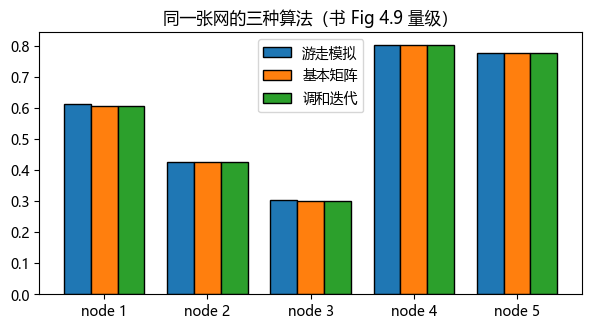

In [13]:
# ===== 书 §4.7 Fig 4.8 =====
# 节点：1..5 内部（(1,1),(1,2),(1,3),(2,2),(2,3)），边界 O(=1V)/Z(=0V)
nb = {1: ["O","O","Z",2], 2: ["Z",1,3,4], 3: ["Z","Z",2,5],
      4: ["O","O",2,5], 5: ["O","O",3,4]}
O, Z = 0.0, 0.0                        # 边界电压
def walk_from(s, r=rng):
    while isinstance(s, int):
        s = nb[s][int(r.integers(4))]
    return 1.0 if s == "O" else 0.0
h_walk = {k: np.mean([walk_from(k) for _ in range(100_000)]) for k in nb}

# 精确：分块 (4.28)(4.30)
inner = [1,2,3,4,5]; bi = {s: i for i, s in enumerate(inner)}
Ph = np.zeros((5,5)); R = np.zeros((5,2))
for s in inner:
    for t in nb[s]:
        if isinstance(t, int): Ph[bi[s], bi[t]] += 0.25
        elif t == "O": R[bi[s], 0] += 0.25
        else: R[bi[s], 1] += 0.25
N = np.linalg.inv(np.eye(5) - Ph)
h_exact = (N @ R @ np.array([1.0, 0.0]))
# 调和方程直接解（迭代平均）
hv = {k: 0.5 for k in inner}
for _ in range(500):
    hv = {k: np.mean([O if t=="Z" else (1.0 if t=="O" else hv[t]) for t in nb[k]]) for k in inner}

print(f"{'节点':>4} {'游走10万':>9} {'基本矩阵':>9} {'调和迭代':>9}")
for s_ in inner:
    print(f"{s_:>4} {h_walk[s_]:>9.4f} {h_exact[bi[s_]]:>9.4f} {hv[s_]:>9.4f}")
fig, ax = plt.subplots(figsize=(7, 3.4))
w = 0.26
hw = [h_walk[s_] for s_ in inner]
he = [h_exact[bi[s_]] for s_ in inner]
hvv = [hv[s_] for s_ in inner]
for k, (dat, lab) in enumerate([(hw, "游走模拟"), (he, "基本矩阵"), (hvv, "调和迭代")]):
    ax.bar(np.arange(5)+ (k-1)*w, dat, w, label=lab, edgecolor="k")
ax.set_xticks(range(5), [f"node {s_}" for s_ in inner]); ax.legend()
ax.set_title("同一张网的三种算法（书 Fig 4.9 量级）")
save(fig, "out-4-12.png"); plt.show()

## 实验 13 kMC 谷粒翻转（书 §4.8，Alg 4.6）

8 位点，A↔B 率 1/5；指数时钟 −ln(1−u)/R；理论稳态 A:B = 5:1。

结束时间 4.12（书 4.78）；B 平均占比 0.24；A:B = 3.13（理论 5）


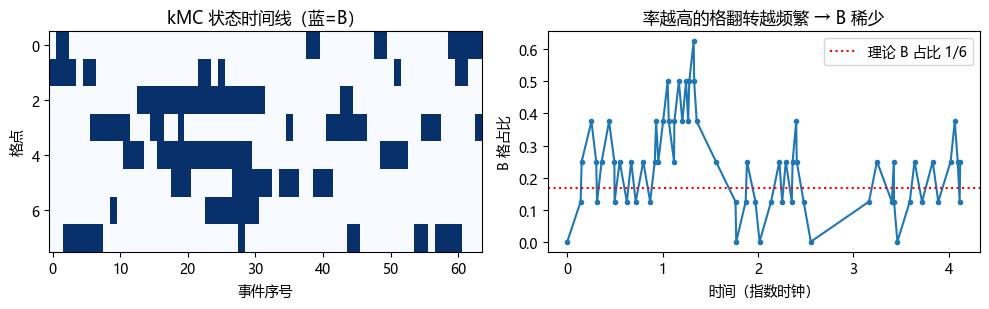

In [14]:
# ===== 书 §4.8 Alg 4.6 =====
nSites, nEvents = 8, 64
state = np.zeros(nSites, dtype=int)        # 0=A, 1=B
t = 0.0; times = [0.0]; fracB = [0.0]; events = []
for e in range(nEvents):
    rates = np.where(state == 0, 1, 5)     # A 翻转率 1，B 翻转率 5
    Rsum = rates.sum()
    t += -np.log(1-rng.random())/Rsum      # 指数时钟
    k = int(np.searchsorted(np.cumsum(rates), rng.random()*Rsum, side="right"))
    state[k] = 1 - state[k]
    times.append(t); fracB.append(state.mean()); events.append(state.copy())
accB = sum(s.sum() for s in events)
accA = nSites*nEvents - accB
print(f"结束时间 {t:.2f}（书 4.78）；B 平均占比 {np.mean(fracB):.2f}；A:B = {accA/accB:.2f}（理论 5）")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].imshow(np.array(events).T, aspect="auto", cmap="Blues", interpolation="nearest")
ax[0].set_xlabel("事件序号"); ax[0].set_ylabel("格点"); ax[0].set_title("kMC 状态时间线（蓝=B）")
ax[1].plot(times, fracB, ".-")
ax[1].axhline(1/6, ls=":", color="r", label="理论 B 占比 1/6")
ax[1].set_xlabel("时间（指数时钟）"); ax[1].set_ylabel("B 格占比"); ax[1].legend()
ax[1].set_title("率越高的格翻转越频繁 → B 稀少")
plt.tight_layout(); save(fig, "out-4-13.png"); plt.show()